In [1]:
import numpy as np
import matplotlib.pyplot as plt
import re

import ase.io as aio



In [2]:
def get_atom_numers(w_uc, n_replica, N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc ):
    #calculate number of atom in the whole config, of every species and per surface.
    #determine the size factor "f"
    
    
    f=n_replica**2 #scaling factor
   
    
    #species
    N_water=int(w_uc*f*2)         #*2 surfaces
    N_H=int(N_water*2)             
    N_O_mag=N_O_mag_uc*f
    N_O=N_O_mag+N_water
    N_Fe=N_Fe_mag_uc*f
    N_atom=N_H+N_O+N_Fe

    #surface
    N_OS=N_OS_uc*f
    N_FeS=N_FeS_uc*f
    N_FeS2= N_FeS2_uc*f
    print(f"size factor f= {f}")
    print(f"N_water = {N_water}")
    print(f"N_H = {N_H}")
    print(f"N_O = {N_O}")
    print(f"N_Fe = {N_Fe}")
    print(f"N_atom = {N_atom}")
    print(f"N_O surface = {N_OS}")
    print(f"N_Fe surface = {N_FeS}")
    print(f"N_Fe surface2 = {N_FeS2}")
    return( f, N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 )

def get_diagonal_lenght( n_replica, L_x_uc, L_y_uc):
    L_x=L_x_uc*n_replica
    L_y=L_y_uc*n_replica
    diag_lenght=np.sqrt(L_x**2+L_y**2) #simulation box xy diagonal lenght to add boundaries 
    print("diag_lenght=" , diag_lenght)
    return(diag_lenght)
    

In [3]:
def wrap_boundary(H, L_x, L_y, L_z):

    for atom in H:
        #x
        if atom[0] < 0:
            print("x out of 0,", atom[0] ,"wrapped in ", L_x+atom[0]  )
            atom[0]=L_x+atom[0]
        elif atom[0] >= L_x:
            print("x out of upper,", atom[0] ,"wrapped in ", atom[0]-L_x  )
            atom[0]=atom[0]-L_x
        #y
        if atom[1] < 0:
            print("y out of 0,", atom[1] ,"wrapped in ", L_y+atom[1]  )
            atom[1]=L_y+atom[1]
        elif atom[1] >= L_y:
            print("y out of upper,", atom[1] ,"wrapped in ", atom[1]-L_y  )
            atom[1]=atom[1]-L_y
        #z
        
    
        if atom[2] < 0:
            #print("z out of 0,", atom[2] ,"wrapped in ", L_z+atom[2]  )
            atom[2]=L_z+atom[2]
        elif atom[2] >= L_z:
            print("z out of upper,", atom[2] ,"wrapped in ", atom[2]-L_z  )
            atom[2]=atom[2]-L_z


def wrap_boundary_xy_not_z(H, L_x, L_y, L_z):
    
    for atom in H:
        #x
        if atom[0] < 0:
            print("x out of 0,", atom[0] ,"wrapped in ", L_x+atom[0]  )
            atom[0]=L_x+atom[0]
        elif atom[0] >= L_x:
            print("x out of upper,", atom[0] ,"wrapped in ", atom[0]-L_x  )
            atom[0]=atom[0]-L_x
        #y
        if atom[1] < 0:
            print("y out of 0,", atom[1] ,"wrapped in ", L_y+atom[1]  )
            atom[1]=L_y+atom[1]
        elif atom[1] >= L_y:
            print("y out of upper,", atom[1] ,"wrapped in ", atom[1]-L_y  )
            atom[1]=atom[1]-L_y
        #z
        if atom[2] < 0:
            #print("z out of 0,", atom[2] ,"wrapped in 0" )
            atom[2]=0
        elif atom[2] >= L_z:
            print("z out of upper,", atom[2] ,"wrapped in ", atom[2]-L_z  )
            atom[2]=L_z

In [4]:
def parser_full_coverage(t_slice,  z_interval_u, z_interval_d,  N_water, N_OS, N_FeS, N_FeS2):
    

    positions=t_slice.get_positions(wrap=True)
    z=positions[:,2]
    #indices species 
    H_indices = np.where(t_slice.get_atomic_numbers()==1)[0]
    O_indices = np.where(t_slice.get_atomic_numbers()==2 )[0]
    Fe_indices = np.where(t_slice.get_atomic_numbers()==3 )[0]
    #indices regions 
    water_indices=np.where( (z > z_interval_u[0] ) |  (z < z_interval_d[0]) )[0]
    
    S_u_indices=np.where(  (z < z_interval_u[0] ) &  (z > z_interval_u[1]) )[0]
    S_d_indices=np.where(  (z < z_interval_d[1] ) &  (z > z_interval_d[0]) )[0]
    
    S2_u_indices=np.where( (z < z_interval_u[1] ) &  (z > z_interval_u[2]) )[0] 
    S2_d_indices=np.where( (z < z_interval_d[2] ) &  (z > z_interval_d[1]) )[0]
    
    
    #H
    H=positions[H_indices]
   
    #O 
    O= positions[list(set(O_indices).intersection(set(water_indices)))]     #water
    OS_u= positions[list(set(O_indices).intersection(set(S_u_indices)))]    #surface up
    OS_d= positions[list(set(O_indices).intersection(set(S_d_indices)))]    #surface down
    #Fe
    FeS_u= positions[list(set(Fe_indices).intersection(set(S_u_indices)))]    #surface up
    FeS_d= positions[list(set(Fe_indices).intersection(set(S_d_indices)))]    #surface down
    FeS2_u= positions[list(set(Fe_indices).intersection(set(S2_u_indices)))]    #2 surface up
    FeS2_d= positions[list(set(Fe_indices).intersection(set(S2_d_indices)))]    #2 surface down
    
    #checks
    if len(H) != N_water*2:
      print(f"H Err:  {len(H) - N_water*2} atom" )
    if len(O) != N_water:
      print(f"O Err: {len(O) - N_water} atom" ) 
    if len(OS_u) != N_OS:
      print(f"OS_u Err: {len(OS_u) - N_OS} atom" )
    if len(OS_d) != N_OS:
      print(f"OS_d Err: {len(OS_d) - N_OS} atom" )
    if len(FeS_u) != N_FeS:
      print(f"FeS_u Err: {len(FeS_u) - N_FeS} atom" )
    if len(FeS_d) != N_FeS:
      print(f"FeS_d Err: {len(FeS_d) - N_FeS} atom" )
    if len(FeS2_u) != N_FeS2:
      print(f"FeS2_u Err: {len(FeS2_u) - N_FeS2} atom" )
    if len(FeS2_d) != N_FeS2:
      print(f"FeS2_d Err: {len(FeS2_d) - N_FeS2} atom" )
     
    
   
    return H, O, OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d
  
  
  
def parser_water_bulk(t_slice):
    

    positions=t_slice.get_positions(wrap=True)
 
    H_indices = np.where(t_slice.get_atomic_numbers()==1)[0]
    O_indices = np.where(t_slice.get_atomic_numbers()==2 )[0]
    
    #H
    H=positions[H_indices]
   
    #O 
    O= positions[O_indices]     #water
    
   
    return H, O

In [5]:
#give #H or #O of water, z of the surface up and down , and max distance from surface
# 1)split atom above and beyond surfaces up to max distance distance. 
# 2) (surface u) shifting z to zero, (surface d) shifting  z to zero  and inverting
def surface_up_down_split(A, z_u, z_d,  max_distance):
    buffer=0.5
    tmp_u=[]
    tmp_d=[]
  
    for atom in A:
        if  z_u - buffer  <atom[2] <  z_u + max_distance  :
            tmp_u.append( [atom[0], atom[1],    atom[2]-z_u ])
        elif z_d -  max_distance < atom[2]<  z_d+buffer:
            tmp_d.append([atom[0], atom[1], -atom[2]+z_d])  
            
    return np.array(tmp_u), np.array(tmp_d)



#y goes to L_y-y
def surface_up_down_split_down_correction(A, z_u, z_d, L_y, max_distance):
    buffer=0.5
    tmp_u=[]
    tmp_d=[]
  
    for atom in A:
        if  z_u - buffer  <atom[2] <  z_u + max_distance  :
            tmp_u.append( [atom[0], atom[1],    atom[2]-z_u ])
        elif z_d -  max_distance < atom[2]<  z_d+buffer:
            tmp_d.append([atom[0], L_y- atom[1], -atom[2]+z_d])   #y to -y it align the oct raws
            
    return np.array(tmp_u), np.array(tmp_d)



#does:  (surface u) shifting z to zero, (surface d) shifting  z to zero  and inverting
def surface_up_down_translate(A_u, A_d, z_u, z_d,  max_distance):
    
    tmp_u=[]
    tmp_d=[]
  
    for atom in A_u:
        if  atom[2] <  z_u + max_distance  :
            tmp_u.append( [atom[0], atom[1],    atom[2]-z_u ])
            
    for atom in A_d:    
       if z_d -  max_distance < atom[2]:
            tmp_d.append([atom[0], atom[1], -atom[2]+z_d])
  


    return tmp_u, tmp_d

#extract z for u and d and put in the same list
def up_down_z_all_t_extractor(H_u, H_d ):
    zH_ud=[]
    for atom in H_u:
            zH_ud.append(atom[2])
    for atom in H_d:
            zH_ud.append(atom[2])

    return zH_ud
#takes: atoms in a layer
#determine exactly the surfaces positions with average of z of all atom in the surface: 
def get_layer_z(A):
    z=A[:,2]
    return np.mean(z), max(z), min(z)


def recenter_magnetite_water(A, z_u, z_d, L_x, L_y, L_z):

    tmp_u=[]
    
    
  
    for atom in A:
        tmp_u.append([atom[0], atom[1], atom[2]-(z_d+z_u)/2])
  


    return np.array(wrap_boundary(tmp_u, L_x, L_y, L_z))


In [121]:
#oct and tet analysis based on oxygens surface layer: OS_u or OS_d as input, box xy diagonal, and  cluster parm epsilon =1

#output diagonal O raws displacment to separate (Fe) oct and tet zones
def get_diagonal_O_raws(OS_u, control, diag_lenght,  epsilon):
    diagonal_projection=[]

    
    for atom in OS_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
        #print(theta)
        if control == 'u':
            diagonal_projection.append(r*np.cos(theta - (np.pi/4)  )   )
        elif control == 'd':
            diagonal_projection.append(r*np.sin(theta - (np.pi/4)  )   )
        else:
            print("control must be 'u' or 'd'")
            return

    #clusterization of diagonal projection of O position in raws
    cluster_diag_proj=[]
    
    cluster_diag_proj.append([diagonal_projection[0]])

    for i, proj in enumerate(diagonal_projection[1:]):
        copy=cluster_diag_proj
     
        for j in range(len(copy)):
            #print(j)
            if np.abs(proj-cluster_diag_proj[j][0])<epsilon:
                cluster_diag_proj[j].append(proj)
                #print("existing")
                break
            elif j==len(copy)-1:      #last round and no match found create new entry
                #print("new")
                cluster_diag_proj.append([proj])
   
    
    #buffering oct region
    cluster_diag_proj=np.sort(cluster_diag_proj)
    diag_raws_buffer=[]   
    if (np.mean(cluster_diag_proj[1])-np.mean(cluster_diag_proj[0]))< (np.mean(cluster_diag_proj[2])-np.mean(cluster_diag_proj[1])): #oct raw first
        for n, cluster in enumerate(cluster_diag_proj):
            if n % 2 == 0:
                diag_raws_buffer.append(np.max(cluster))
            else:
                diag_raws_buffer.append(np.min(cluster))
    else: #tet raw first
        for n, cluster in enumerate(cluster_diag_proj):
            if n % 2 == 0:
                diag_raws_buffer.append(np.min(cluster))
            else:
                diag_raws_buffer.append(np.max(cluster))
   
    if control == 'u':
        diag_raws_buffer.insert(0,0)
        diag_raws_buffer.append(diag_lenght)
    else:
        diag_raws_buffer.insert(0,-diag_lenght/2)
        diag_raws_buffer.append(diag_lenght/2)
    #print(diag_raws_buffer)
    return diag_raws_buffer
        
        
    
#oct/tet regions atomic separation; inside O raws = oct, outside = tet: 
def oct_tet_split_combo(combo, diag_raw , control):
      
    oct_combo=[]
    tet_combo=[]
    
    
    for atom , bond in combo:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
    
        if control == 'u':
            diagonal_projection=(r*np.cos(theta - (np.pi/4)  ))     #up cos raws   \\\\\           
        elif control == 'd':
            diagonal_projection=(r*np.sin(theta - (np.pi/4)  ))     #down sin raws  /////   
            
        else:  
            print("control must be 'u' or 'd'")
            return   
        
        if diagonal_projection <diag_raw[0] or diagonal_projection > diag_raw[-1]:  #inbound check
                print("OUT of bounds: diag =" , diagonal_projection, "cartesian =", atom)
                
        if (diag_raw[2]-diag_raw[1])<(diag_raw[3]-diag_raw[2]):           #check if the first raw (the zero is the border)is oct or tet (if T == oct if F ==tet )
            # first raw is oct
            #if diagonal projection in (diag_raw[2n],diag_raw[2n+1])   then tet region  even!
            #if diagonal projection in (diag_raw[2n+1],diag_raw[2n+2]) then oct region odd!
            
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        tet_combo.append([atom, bond]) #n even ==> outside O raws == tet region
                    else:
                        oct_combo.append([atom, bond]) #n odd ==> inside O raws == oct region
                    break
        else:
            #first raw is tet (then vice versa)
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        oct_combo.append([atom, bond]) #n even ==> inside O raws == oct region
                    else:
                        tet_combo.append([atom, bond]) #n odd ==> outside O raws == tet region
                    break
        
    if len(oct_combo)+len(tet_combo) != len(combo):
        print("MISSING TET/OCT ATOM: ",len(combo)-  (len(oct_combo)+len(tet_combo))) 
    return oct_combo,  tet_combo

In [122]:
def vector_distance_pbc(u,v , L_x, L_y, L_z):
    difference=[]
    
    dx=u[0]-v[0]
    dy=u[1]-v[1]
    dz=u[2]-v[2]
    
    if np.abs(dx) <= L_x/2:
        difference.append(dx)
    elif dx>0:
        difference.append(dx - L_x)
    else:
        difference.append(dx + L_x)
    
    if np.abs(dy) <= L_y/2:
        difference.append(dy)
    elif dy>0:
        difference.append(dy- L_y)
    else:
        difference.append(dy + L_y)
    
    if np.abs(dz) <= L_z/2:
        difference.append(dz)
    elif dz>0:
        difference.append(dz- L_z)
    else:
        difference.append(dz+ L_z)
    
    return np.array(difference)


import math
def cartesian_internal(u):  
    x=u[0]
    y=u[1]
    z=u[2]
    # Calculate radial distance
    r = math.sqrt(x**2 + y**2 + z**2)

    # Calculate polar angle (theta)
    theta = math.acos(z / r) if r != 0 else 0

    # Calculate azimuthal angle (phi)
    phi = math.atan2(y, x)
    

    return r, theta, phi   

In [123]:
def get_O_cartesian_OH_internal(H_u_indx, O, H, L_x,L_y, z_max_vacuum, t):
    water_dipole=[]
    OHHH=[]
    OH_water=[]
    OH=[]
    O_alone=[]
    
    
    for i , H_index in enumerate(H_u_indx):

        if len(H_index)==0: 
                #if  O[i][2]>3.7:
                #       print(t,"attention! z O alone =",  O[i][2] )
                O_alone.append(O[i])

        elif len(H_index)==1: 

                OH_internal=cartesian_internal(vector_distance_pbc(H[H_index[0]],O[i]  , L_x, L_y, z_max_vacuum))
                OH.append([O[i],OH_internal])
                
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OH =",  O[i][2] )
                
        elif len(H_index)==2:
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                dipole=OH_cartesian_0+OH_cartesian_1
                
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                dipole_internal=cartesian_internal(dipole)
                
                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
                water_dipole.append([O[i],dipole_internal] )

        elif len(H_index)==3:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OHHH =",  O[i][2] )
                
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_2=vector_distance_pbc(H[H_index[2]], O[i] , L_x, L_y, z_max_vacuum)
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                OH_internal_2=cartesian_internal(OH_cartesian_2)
                
                OHHH.append([O[i],OH_internal_0])
                OHHH.append([O[i],OH_internal_1])
                OHHH.append([O[i],OH_internal_2])
                
        else:
              print( "attention! found H*O=", H_index, "at z=", O[i][2])  
    return water_dipole , OH_water , OH, OHHH, O_alone

In [124]:
def get_O_cartesian_OH_internal_OHHH_included(H_u_indx, O, H, L_x,L_y, z_max_vacuum, z_max, t):
    water_dipole=[]
    OHHH=[]
    OH_water=[]
    OH=[]
    OH_count=0
    OHHH_count=0
    for i , H_index in enumerate(H_u_indx):

        if len(H_index)==1: 

                OH_internal=cartesian_internal(vector_distance_pbc(H[H_index[0]],O[i]  , L_x, L_y, z_max_vacuum))
                OH.append([O[i],OH_internal])
                
                if  3.7< O[i][2]<z_max:
                       print(t,"attention! z OH =",  O[i][2] )
                       OH_count+=1
                
        elif len(H_index)==2:
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                dipole=OH_cartesian_0+OH_cartesian_1
                
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                dipole_internal=cartesian_internal(dipole)
                
                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
                water_dipole.append([O[i],dipole_internal] )

        elif len(H_index)==3:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OHHH =",  O[i][2] )
                
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_2=vector_distance_pbc(H[H_index[2]], O[i] , L_x, L_y, z_max_vacuum)
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                OH_internal_2=cartesian_internal(OH_cartesian_2)
                
                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
                OH_water.append([O[i],OH_internal_2])
                if  3.7< O[i][2]<z_max:
                       print(t,"attention! z H3O =",  O[i][2] )
                       OHHH_count+=1
                
        else:
              print( "attention! found H4O=", H_index, "at z=", O[i][2])  
    return water_dipole , OH_water , OH, OH_count, OHHH_count

In [125]:
def OH_z_layer_grouping(O_bond_format,  layer_bins):
    

    # Group arrays based on bins
    grouped_arrays = {category: [] for category in layer_bins}

    for combo in O_bond_format:
        O_z=combo[0][2]
        OH_internal=combo[1]
        for category, condition in layer_bins.items():
            if condition(O_z):
                grouped_arrays[category].append(OH_internal)
                break  # Break out of the loop after categorizing the array

    return grouped_arrays


In [126]:

def init_bins_rho_theta_phi( n_bin, delta):


    
    
    rho_bins = np.linspace(delta - delta/3, delta , n_bin) 
    theta_bins = np.linspace(-1, 1, n_bin) 
    phi_bins = np.linspace(-np.pi, np.pi , n_bin) 
    
    rho_bins_centers=(rho_bins[1:]+rho_bins[:-1])/2
    theta_bins_centers=(theta_bins[1:]+theta_bins[:-1])/2
    phi_bins_centers=(phi_bins[1:]+phi_bins[:-1])/2   
    
    
    
    return   rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers

def init_hist_rho_theta_phi(layer_bins, n_bin):

    
    rho_hist = {}
    theta_hist = {}
    phi_hist={}
    
    for name in layer_bins.keys():
        rho_hist[name]  =[0]*(n_bin-1)
        theta_hist[name]=[0]*(n_bin-1)
        phi_hist[name]  =[0]*(n_bin-1)

    
    return  rho_hist , theta_hist, phi_hist


In [127]:

def sum_hist_rho_theta_phi(OH_grouped, rho_hist, theta_hist, phi_hist, rho_bins, theta_bins, phi_bins ,density_bool):



    for layer, bonds in OH_grouped.items():
        if len(bonds) !=0:
            rho=np.transpose(np.array(bonds))[0]
            theta=np.transpose(np.array(bonds))[1]
            phi=np.transpose(np.array(bonds))[2]    
            
            phi_weights=np.sin(theta)
            rho_hist[layer]  +=np.histogram(rho, bins=rho_bins, density=density_bool)[0]
            theta_hist[layer]+=np.histogram(np.cos(theta), bins=theta_bins,  density=density_bool)[0]
            phi_hist[layer]  +=np.histogram(phi, bins=phi_bins, weights=phi_weights,  density=density_bool )[0]   

    return  rho_hist, theta_hist, phi_hist 

def sum_hist_theta_phi(OH_grouped, theta_hist, phi_hist, theta_bins, phi_bins ,density_bool):

    for layer, bonds in OH_grouped.items():
        if len(bonds) !=0:
            theta=np.transpose(np.array(bonds))[1]
            phi=np.transpose(np.array(bonds))[2]    
            
            phi_weights=np.sin(theta)

            theta_hist[layer]+=np.histogram(np.cos(theta), bins=theta_bins,  density=density_bool)[0]
            phi_hist[layer]  +=np.histogram(phi, bins=phi_bins, weights=phi_weights,  density=density_bool )[0]   

    return theta_hist, phi_hist   
    

In [128]:
def dict_bins_maker(names,layers):  #name of the z layers and layers contain  min and max value
    layer_bins={}
    

    for i, key in enumerate(names):
        layer_bins[key] = (lambda i=i: lambda x: layers[i] < x <= layers[i + 1])()
    
    return  layer_bins


def dict_bins_maker_Lz_buffer(names,layers,z_max):  #name of the z layers and layers contain  min and max value
    layer_bins={}
    

    for i, key in enumerate(names):
        if layers[i]==0:
            layer_bins[key] = (lambda i=i: lambda x: (layers[i] < x <= layers[i + 1]) or (x >= z_max))()
        else:    
            layer_bins[key] = (lambda i=i: lambda x: layers[i] < x <= layers[i + 1])()
    
    return  layer_bins

In [129]:
# FIRST PAPER
# magnetite 1 u.c. data
#8.396 0.0 0.0
#0.0 8.396 0.0
#0.0 0.0 34.7337          
#O Fe
#72 50

#Full Coverage L_z = 71.4784

#number of O/Fe atom per uc
N_O_mag_uc=64               #second paper  N_O_mag_uc=64    
N_Fe_mag_uc=44              #second paper  N_Fe_mag_uc=44
#box lenght unit cell!
L_x_uc=8.396                #second paper same (8.396)
L_y_uc=8.396

#SCV structure (1uc)
N_OS_uc=8    # number oxygen in first outer layer/uc
N_FeS_uc=4   # number of iron in first outer layer/uc
N_FeS2_uc=3  # number of iron  second/outer layer/uc


trj="./full_coverage/run_2/trjmagnetite.dump"      #path to trj #IMPORTANT: trj must be ordered by z and clustered by atom
#water per u.c. per surface
w_uc=68                                  #second paper full= 68
n_replica=4                              #if it is replicated 2x2 n_replica=2        

#boundaries #only for full coverage
z_interval_u=[42.5, 41.1, 40.1]     
z_interval_d=[26.29, 27.45, 28.5]   

#size factor, tot number of H, O, Fe, number of O in the magnetite surface and Fe in the 2 outermost layers 
f, N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 =get_atom_numers(w_uc, n_replica, N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc )

diag_lenght= get_diagonal_lenght( n_replica, L_x_uc, L_y_uc)

L_x=L_x_uc*n_replica
L_y=L_y_uc*n_replica
L_z = 71.4784



#oct/tet
control_u='u'
control_d='d'  

size factor f= 16
N_water = 2176
N_H = 4352
N_O = 3200
N_Fe = 704
N_atom = 8256
N_O surface = 128
N_Fe surface = 64
N_Fe surface2 = 48
diag_lenght= 47.49494827873803


In [96]:
def safe_concatenate(a,b):
    if len(a)==0:
        return b
    elif len(b)==0:
        return a
    else:
        return np.concatenate((a,b),axis=0) 

    

In [ ]:

from scipy.spatial import cKDTree

#BULK WQATER / SURFACE O SEPARETED
   
delta=1.35
z_max=10             #max distance from the surface for O    
z_max_H=z_max+delta           #max distance from the surface for H (delta above to include the missing H at the cut)
z_max_vacuum= z_max+3*delta   #another delta of vacuum distance on top to avoid wrong PBC count


#H tree box for bonding
box_size = np.array([L_x, L_y, z_max_vacuum])  


#histograms
n_bins=100
#cutoff_rho=2*delta
layers=[0, 0.8, 2.2 , 3.7]
# Define your bins
names=["l_"+str(i) for i in np.arange(0,len(layers)-1)]


layer_bins=dict_bins_maker(names,layers)

#initilize  rho theta and phi bins and bins centers
rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta)
#initialize histograms with zeros
rho_hist_OH_oct     , theta_hist_OH_oct     , phi_hist_OH_oct     =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_water_oct  , theta_hist_water_oct  , phi_hist_water_oct  =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_dipole_oct , theta_hist_dipole_oct , phi_hist_dipole_oct =init_hist_rho_theta_phi(layer_bins, n_bins)   

rho_hist_OH_tet     , theta_hist_OH_tet     , phi_hist_OH_tet     =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_water_tet  , theta_hist_water_tet  , phi_hist_water_tet  =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_dipole_tet , theta_hist_dipole_tet , phi_hist_dipole_tet =init_hist_rho_theta_phi(layer_bins, n_bins)
 

t=0
for t_slice in aio.iread(trj,format='lammps-dump-text'):
    
     #parsing
     H, O,  OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d = parser_full_coverage(t_slice,  z_interval_u, z_interval_d,  N_water, N_OS, N_FeS, N_FeS2)
     
     if t % 2 == 0:   #it does every N steps
          #get layer update infos of surfaces 
          
          #first 
          S_u, S_u_min, S_u_max =get_layer_z(np.concatenate((OS_u,FeS_u),axis=0 ))
          S_d, S_d_min, S_d_max =get_layer_z(np.concatenate((OS_d,FeS_d),axis=0 )) 
          
          #oct/tet raws
          diag_raw_u=get_diagonal_O_raws(OS_u, control_u, diag_lenght, 1 )
          diag_raw_d=get_diagonal_O_raws(OS_d, control_u, diag_lenght, 1 )
           
     #add oxygen at surface to get the OH bond of dissociation
     all_O=np.concatenate((O,OS_u,OS_d))
      
     # translate to 0 the surfaces (and invert the d)
     O_u, O_d=surface_up_down_split_down_correction(all_O, S_u, S_d, L_y, z_max)   # down correction: y is inverted to align the down raws
     H_u, H_d=surface_up_down_split_down_correction(H    , S_u, S_d, L_y, z_max_H)       
     
     
     #O_u, O_d=surface_up_down_split(all_O, S_u, S_d, z_max)   
     #H_u, H_d=surface_up_down_split(H    , S_u, S_d, z_max_H) 
     

     # wrap possible out of box in xy direction
     wrap_boundary(O_u, L_x, L_y, z_max_vacuum)  #the O at the surface with negative values are mapped at z_max_vacuum
     wrap_boundary(O_d, L_x, L_y, z_max_vacuum)
     wrap_boundary(H_u, L_x, L_y, z_max_vacuum)       #no H should be out of z boundary (<= z_max_H) only for x y errors
     wrap_boundary(H_d, L_x, L_y, z_max_vacuum)
     
     
     
     #H_u/d_index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O 
     tree = cKDTree(data=H_u, leafsize=H_u.shape[0], boxsize= box_size)  #makes a tree of Hs
     H_u_indx = tree.query_ball_point(O_u, delta)                        #assign every H to an O within the cutoff and make the list of list H
     #down
     tree      = cKDTree(data=H_d, leafsize=H_d.shape[0], boxsize= box_size)
     H_d_indx = tree.query_ball_point(O_d, delta)
   
   
     #extract from the H_u_indx the Oxygen in cartesian and the OH(s)in polar:
     #the output is then a list of pair [O_vect, OH]
     dipole_u , OH_water_u , OH_u,O_HHH_u, O_alone_u=get_O_cartesian_OH_internal(H_u_indx, O_u, H_u, L_x,L_y, z_max_vacuum, t)   #not periodic distance for the z direction
     dipole_d , OH_water_d , OH_d,O_HHH_d, O_alone_d=get_O_cartesian_OH_internal(H_d_indx, O_d, H_d, L_x,L_y, z_max_vacuum,  t)      #not periodic distance for the z direction
     
     #OCT/TET splitting #all control are up because of the down correction while splitting up and down
     #up
     dipole_u_oct,   dipole_u_tet   =oct_tet_split_combo(dipole_u,   diag_raw_u , control_u )
     OH_water_u_oct, OH_water_u_tet =oct_tet_split_combo(OH_water_u, diag_raw_u , control_u )
     OH_u_oct,       OH_u_tet       =oct_tet_split_combo(OH_u,       diag_raw_u , control_u )
     #down
     dipole_d_oct,   dipole_d_tet   =oct_tet_split_combo(dipole_d,   diag_raw_d , control_u )
     OH_water_d_oct, OH_water_d_tet =oct_tet_split_combo(OH_water_d, diag_raw_d , control_u )
     OH_d_oct,       OH_d_tet       =oct_tet_split_combo(OH_d,       diag_raw_d , control_u )
       
     
     
     
     #unify up and down oct and up down tet surface
     #dipole_oct  =np.concatenate((dipole_u_oct,   dipole_d_oct),   axis=0)
     #OH_water_oct=np.concatenate((OH_water_u_oct, OH_water_d_oct), axis=0)
     #OH_oct      =np.concatenate((OH_u_oct,       OH_d_oct),       axis=0)
     dipole_oct  =safe_concatenate(dipole_u_oct,   dipole_d_oct)
     OH_water_oct=safe_concatenate(OH_water_u_oct, OH_water_d_oct)
     OH_oct=safe_concatenate(OH_u_oct, OH_d_oct)
  
     
     #dipole_tet  =np.concatenate((dipole_u_tet,   dipole_d_tet),   axis=0)
     #OH_water_tet=np.concatenate((OH_water_u_tet, OH_water_d_tet), axis=0)
     #OH_tet      =np.concatenate((OH_u_tet,       OH_d_tet),       axis=0)
     dipole_tet  =safe_concatenate(dipole_u_tet,   dipole_d_tet)
     OH_water_tet=safe_concatenate(OH_water_u_tet, OH_water_d_tet)
     OH_tet=safe_concatenate(OH_u_tet, OH_d_tet)
    
    
     
     #use the info of the z Oxygen to group the OH by their heights: output is dictonary with layer_bins keys and vlues OH in internal
     dipole_z_oct  = OH_z_layer_grouping(dipole_oct,   layer_bins)
     OH_water_z_oct= OH_z_layer_grouping(OH_water_oct, layer_bins)
     OH_z_oct      = OH_z_layer_grouping(OH_oct,       layer_bins)
     
     dipole_z_tet  = OH_z_layer_grouping(dipole_tet,   layer_bins)
     OH_water_z_tet= OH_z_layer_grouping(OH_water_tet, layer_bins)
     OH_z_tet      = OH_z_layer_grouping(OH_tet,       layer_bins)
     
     
     density_bool=False
     rho_hist_OH_oct,     theta_hist_OH_oct,     phi_hist_OH_oct     = sum_hist_rho_theta_phi(OH_z_oct, rho_hist_OH_oct, theta_hist_OH_oct, phi_hist_OH_oct, rho_bins, theta_bins, phi_bins, density_bool)
     rho_hist_water_oct,  theta_hist_water_oct,  phi_hist_water_oct  = sum_hist_rho_theta_phi(OH_water_z_oct, rho_hist_water_oct, theta_hist_water_oct, phi_hist_water_oct, rho_bins, theta_bins, phi_bins,density_bool )
     rho_hist_dipole_oct, theta_hist_dipole_oct, phi_hist_dipole_oct = sum_hist_rho_theta_phi(dipole_z_oct, rho_hist_dipole_oct, theta_hist_dipole_oct, phi_hist_dipole_oct, rho_bins, theta_bins, phi_bins, density_bool )
     rho_hist_OH_tet,     theta_hist_OH_tet,     phi_hist_OH_tet     = sum_hist_rho_theta_phi(OH_z_tet, rho_hist_OH_tet, theta_hist_OH_tet, phi_hist_OH_tet, rho_bins, theta_bins, phi_bins, density_bool)
     rho_hist_water_tet,  theta_hist_water_tet,  phi_hist_water_tet  = sum_hist_rho_theta_phi(OH_water_z_tet, rho_hist_water_tet, theta_hist_water_tet, phi_hist_water_tet, rho_bins, theta_bins, phi_bins,density_bool )
     rho_hist_dipole_tet, theta_hist_dipole_tet, phi_hist_dipole_tet = sum_hist_rho_theta_phi(dipole_z_tet, rho_hist_dipole_tet, theta_hist_dipole_tet, phi_hist_dipole_tet, rho_bins, theta_bins, phi_bins, density_bool )

     t+=1
     
     

In [152]:

from scipy.spatial import cKDTree


   
delta=1.35
z_max=10             #max distance from the surface for O    
z_max_H=z_max+delta           #max distance from the surface for H (delta above to include the missing H at the cut)
z_max_vacuum= z_max+3*delta   #another delta of vacuum distance on top to avoid wrong PBC count


#H tree box for bonding
box_size = np.array([L_x, L_y, z_max_vacuum])  


#histograms
n_bins=100
#cutoff_rho=2*delta
layers=[0, 0.8, 2.2 , 3.7]
# Define your bins
names=["l_"+str(i) for i in np.arange(0,len(layers)-1)]


layer_bins=dict_bins_maker(names,layers)

#initilize  rho theta and phi bins and bins centers
rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta)
#initialize histograms with zeros
rho_hist_OH_oct     , theta_hist_OH_oct     , phi_hist_OH_oct     =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_water_oct  , theta_hist_water_oct  , phi_hist_water_oct  =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_dipole_oct , theta_hist_dipole_oct , phi_hist_dipole_oct =init_hist_rho_theta_phi(layer_bins, n_bins)   

rho_hist_OH_tet     , theta_hist_OH_tet     , phi_hist_OH_tet     =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_water_tet  , theta_hist_water_tet  , phi_hist_water_tet  =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_dipole_tet , theta_hist_dipole_tet , phi_hist_dipole_tet =init_hist_rho_theta_phi(layer_bins, n_bins)
 

t=0
for t_slice in aio.iread(trj,format='lammps-dump-text'):
    
     #parsing
     H, O,  OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d = parser_full_coverage(t_slice,  z_interval_u, z_interval_d,  N_water, N_OS, N_FeS, N_FeS2)
     
     if t % 2 == 0:   #it does every N steps
          #get layer update infos of surfaces 
          
          #first 
          S_u, S_u_min, S_u_max =get_layer_z(np.concatenate((OS_u,FeS_u),axis=0 ))
          S_d, S_d_min, S_d_max =get_layer_z(np.concatenate((OS_d,FeS_d),axis=0 )) 
          
          #oct/tet raws
          diag_raw_u=get_diagonal_O_raws(OS_u, control_u, diag_lenght, 1 )
          diag_raw_d=get_diagonal_O_raws(OS_d, control_u, diag_lenght, 1 )
           
     #add oxygen at surface to get the OH bond of dissociation
     all_O=np.concatenate((O,OS_u,OS_d))
      
     # translate to 0 the surfaces (and invert the d)
     O_u, O_d=surface_up_down_split_down_correction(all_O, S_u, S_d, L_y, z_max)   # down correction: y is inverted to align the down raws
     H_u, H_d=surface_up_down_split_down_correction(H    , S_u, S_d, L_y, z_max_H)       
     
     
     #O_u, O_d=surface_up_down_split(all_O, S_u, S_d, z_max)   
     #H_u, H_d=surface_up_down_split(H    , S_u, S_d, z_max_H) 
     

     # wrap possible out of box in xy direction
     wrap_boundary(O_u, L_x, L_y, z_max_vacuum)  #the O at the surface with negative values are mapped at z_max_vacuum
     wrap_boundary(O_d, L_x, L_y, z_max_vacuum)
     wrap_boundary(H_u, L_x, L_y, z_max_vacuum)       #no H should be out of z boundary (<= z_max_H) only for x y errors
     wrap_boundary(H_d, L_x, L_y, z_max_vacuum)
     
     
     
     #H_u/d_index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O 
     tree = cKDTree(data=H_u, leafsize=H_u.shape[0], boxsize= box_size)  #makes a tree of Hs
     H_u_indx = tree.query_ball_point(O_u, delta)                        #assign every H to an O within the cutoff and make the list of list H
     #down
     tree      = cKDTree(data=H_d, leafsize=H_d.shape[0], boxsize= box_size)
     H_d_indx = tree.query_ball_point(O_d, delta)
   
   
     #extract from the H_u_indx the Oxygen in cartesian and the OH(s)in polar:
     #the output is then a list of pair [O_vect, OH]
     dipole_u , OH_water_u , OH_u,O_HHH_u, O_alone_u=get_O_cartesian_OH_internal(H_u_indx, O_u, H_u, L_x,L_y, z_max_vacuum, t)   #not periodic distance for the z direction
     dipole_d , OH_water_d , OH_d,O_HHH_d, O_alone_d=get_O_cartesian_OH_internal(H_d_indx, O_d, H_d, L_x,L_y, z_max_vacuum,  t)      #not periodic distance for the z direction
     
     #OCT/TET splitting #all control are up because of the down correction while splitting up and down
     #up
     dipole_u_oct,   dipole_u_tet   =oct_tet_split_combo(dipole_u,   diag_raw_u , control_u )
     OH_water_u_oct, OH_water_u_tet =oct_tet_split_combo(OH_water_u, diag_raw_u , control_u )
     OH_u_oct,       OH_u_tet       =oct_tet_split_combo(OH_u,       diag_raw_u , control_u )
     #down
     dipole_d_oct,   dipole_d_tet   =oct_tet_split_combo(dipole_d,   diag_raw_d , control_u )
     OH_water_d_oct, OH_water_d_tet =oct_tet_split_combo(OH_water_d, diag_raw_d , control_u )
     OH_d_oct,       OH_d_tet       =oct_tet_split_combo(OH_d,       diag_raw_d , control_u )
       
     
     
     
     #unify up and down oct and up down tet surface
     #dipole_oct  =np.concatenate((dipole_u_oct,   dipole_d_oct),   axis=0)
     #OH_water_oct=np.concatenate((OH_water_u_oct, OH_water_d_oct), axis=0)
     #OH_oct      =np.concatenate((OH_u_oct,       OH_d_oct),       axis=0)
     dipole_oct  =safe_concatenate(dipole_u_oct,   dipole_d_oct)
     OH_water_oct=safe_concatenate(OH_water_u_oct, OH_water_d_oct)
     OH_oct=safe_concatenate(OH_u_oct, OH_d_oct)
  
     
     #dipole_tet  =np.concatenate((dipole_u_tet,   dipole_d_tet),   axis=0)
     #OH_water_tet=np.concatenate((OH_water_u_tet, OH_water_d_tet), axis=0)
     #OH_tet      =np.concatenate((OH_u_tet,       OH_d_tet),       axis=0)
     dipole_tet  =safe_concatenate(dipole_u_tet,   dipole_d_tet)
     OH_water_tet=safe_concatenate(OH_water_u_tet, OH_water_d_tet)
     OH_tet=safe_concatenate(OH_u_tet, OH_d_tet)
    
    
     
     #use the info of the z Oxygen to group the OH by their heights: output is dictonary with layer_bins keys and vlues OH in internal
     dipole_z_oct  = OH_z_layer_grouping(dipole_oct,   layer_bins)
     OH_water_z_oct= OH_z_layer_grouping(OH_water_oct, layer_bins)
     OH_z_oct      = OH_z_layer_grouping(OH_oct,       layer_bins)
     
     dipole_z_tet  = OH_z_layer_grouping(dipole_tet,   layer_bins)
     OH_water_z_tet= OH_z_layer_grouping(OH_water_tet, layer_bins)
     OH_z_tet      = OH_z_layer_grouping(OH_tet,       layer_bins)
     
     
     density_bool=False
     rho_hist_OH_oct,     theta_hist_OH_oct,     phi_hist_OH_oct     = sum_hist_rho_theta_phi(OH_z_oct, rho_hist_OH_oct, theta_hist_OH_oct, phi_hist_OH_oct, rho_bins, theta_bins, phi_bins, density_bool)
     rho_hist_water_oct,  theta_hist_water_oct,  phi_hist_water_oct  = sum_hist_rho_theta_phi(OH_water_z_oct, rho_hist_water_oct, theta_hist_water_oct, phi_hist_water_oct, rho_bins, theta_bins, phi_bins,density_bool )
     rho_hist_dipole_oct, theta_hist_dipole_oct, phi_hist_dipole_oct = sum_hist_rho_theta_phi(dipole_z_oct, rho_hist_dipole_oct, theta_hist_dipole_oct, phi_hist_dipole_oct, rho_bins, theta_bins, phi_bins, density_bool )
     rho_hist_OH_tet,     theta_hist_OH_tet,     phi_hist_OH_tet     = sum_hist_rho_theta_phi(OH_z_tet, rho_hist_OH_tet, theta_hist_OH_tet, phi_hist_OH_tet, rho_bins, theta_bins, phi_bins, density_bool)
     rho_hist_water_tet,  theta_hist_water_tet,  phi_hist_water_tet  = sum_hist_rho_theta_phi(OH_water_z_tet, rho_hist_water_tet, theta_hist_water_tet, phi_hist_water_tet, rho_bins, theta_bins, phi_bins,density_bool )
     rho_hist_dipole_tet, theta_hist_dipole_tet, phi_hist_dipole_tet = sum_hist_rho_theta_phi(dipole_z_tet, rho_hist_dipole_tet, theta_hist_dipole_tet, phi_hist_dipole_tet, rho_bins, theta_bins, phi_bins, density_bool )

     t+=1
     
     

/data/home/salvatorer26/.local/lib/python3.8/site-packages/numpy/core/fromnumeric.py:1003: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  a = asanyarray(a).copy(order="K")


y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.58400312754 wrapped in  3.1275399976493645e-06
FeS_d Err: 1 atom
FeS2_d Err: -1 atom
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0


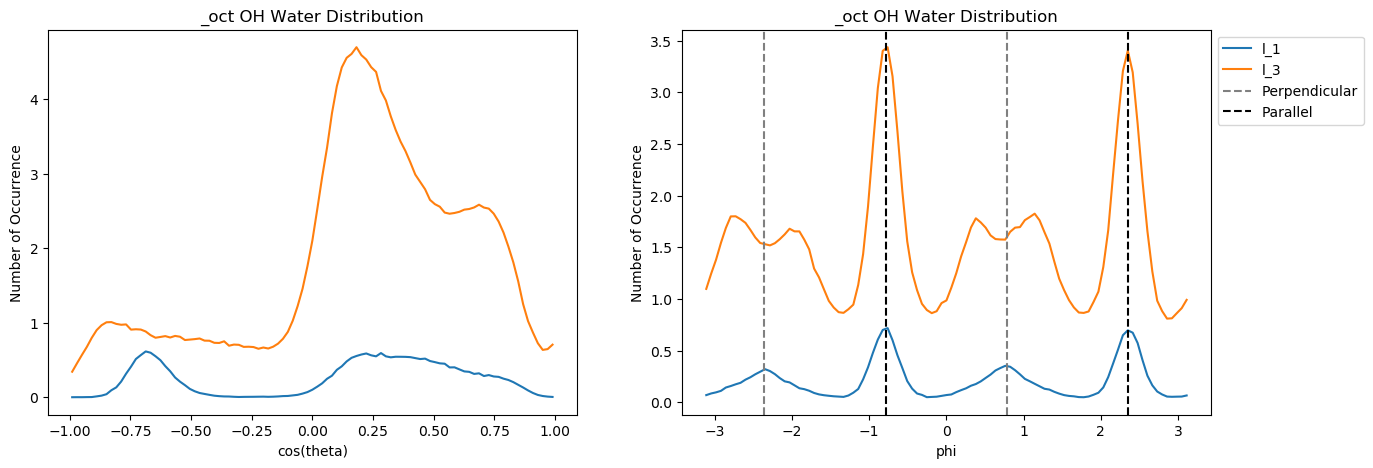

In [154]:
# Set up subplots with 1 row and 3 columns

hist_category='water'
region='_oct'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'

# Iterate through the axes and plot on each
for ax, name_internal, x_name in  zip(axes, name_internals, x_labels):
    for l in layer_bins.keys():
        if all(element == 0 for element in eval(name_internal+str_hist+hist_category+region)[l]):
            continue
        else:
            ax.plot( eval(name_internal+str_bins_centers)  , eval(name_internal+str_hist+hist_category+region)[l]/t, label=l  ) 
            ax.set_title(f'{region} OH Water Distribution')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Number of Occurrence')
ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
ax.axvline(x=-2.3562, color='grey', linestyle='--')
ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
ax.axvline(x=-0.7854, color='black', linestyle='--'  )    
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
#plt.tight_layout()

#plt.savefig(f"angular_Water_OH", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

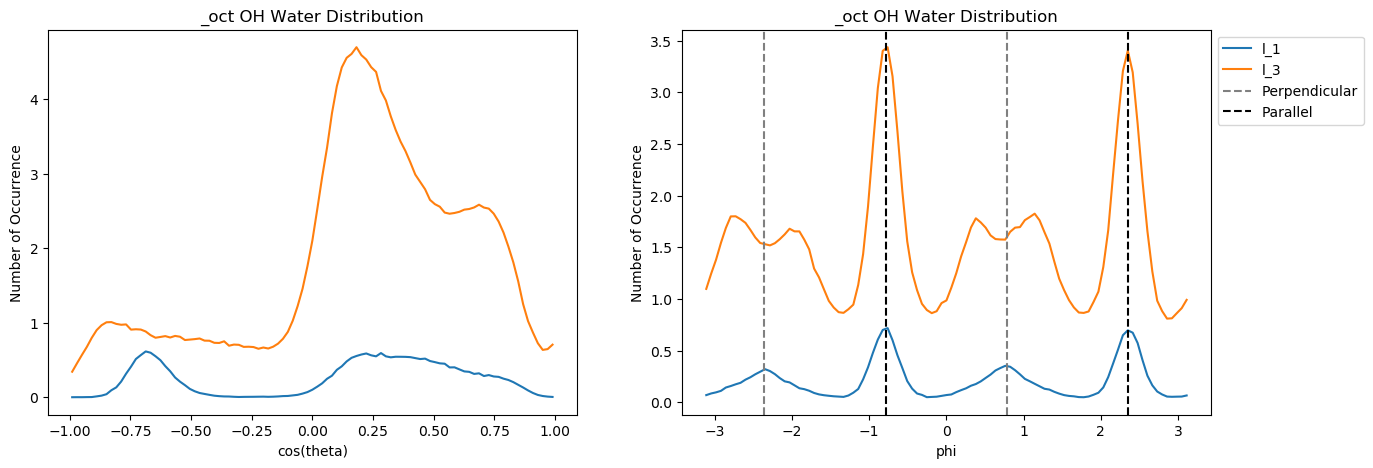

In [155]:
# Set up subplots with 1 row and 3 columns

hist_category='water'
region='_oct'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'

# Iterate through the axes and plot on each
for ax, name_internal, x_name in  zip(axes, name_internals, x_labels):
    for l in layer_bins.keys():
        if all(element == 0 for element in eval(name_internal+str_hist+hist_category+region)[l]):
            continue
        else:
            ax.plot( eval(name_internal+str_bins_centers)  , eval(name_internal+str_hist+hist_category+region)[l]/t, label=l  ) 
            ax.set_title(f'{region} OH Water Distribution')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Number of Occurrence')
ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
ax.axvline(x=-2.3562, color='grey', linestyle='--')
ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
ax.axvline(x=-0.7854, color='black', linestyle='--'  )    
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
#plt.tight_layout()

#plt.savefig(f"angular_Water_OH", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

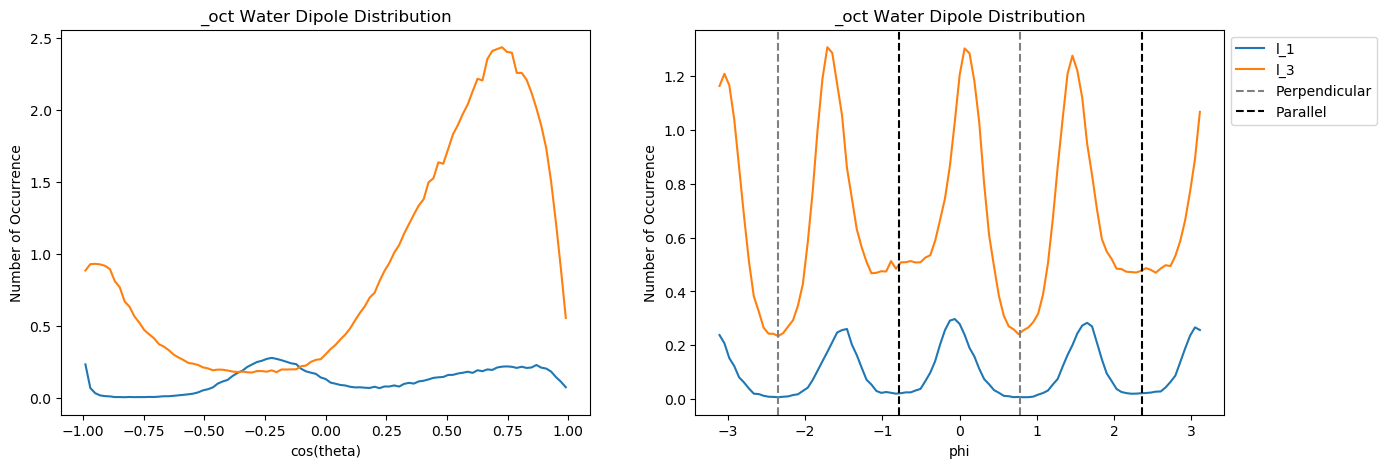

In [158]:
# Set up subplots with 1 row and 3 columns

hist_category='dipole'
region='_oct'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'

# Iterate through the axes and plot on each
for ax, name_internal, x_name in  zip(axes, name_internals, x_labels):
    for l in layer_bins.keys():
        if all(element == 0 for element in eval(name_internal+str_hist+hist_category+region)[l]):
            continue
        else:
               
            ax.plot( eval(name_internal+str_bins_centers)  , eval(name_internal+str_hist+hist_category+region)[l]/t, label=l  ) 
            ax.set_title(f'{region} Water Dipole Distribution')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Number of Occurrence')
ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
ax.axvline(x=-2.3562, color='grey', linestyle='--')
ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
ax.axvline(x=-0.7854, color='black', linestyle='--'  )

ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
#plt.tight_layout()
#plt.savefig(f"angular_Water_dipole", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

In [147]:
print(t)

3970


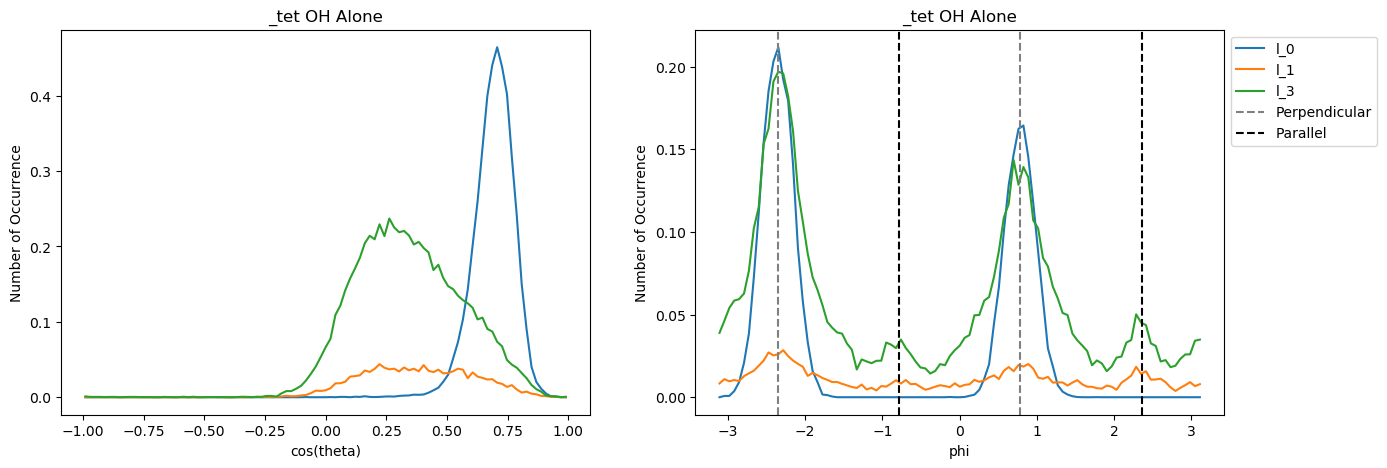

In [163]:
# Set up subplots with 1 row and 3 columns

hist_category='OH'
region='_tet'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'

# Iterate through the axes and plot on each
for ax, name_internal, x_name in  zip(axes, name_internals, x_labels):
    for l in layer_bins.keys():
        if all(element == 0 for element in eval(name_internal+str_hist+hist_category+region)[l]):
            continue
        else:
            ax.plot( eval(name_internal+str_bins_centers)  , eval(name_internal+str_hist+hist_category+region)[l]/t, label=l  ) 
            ax.set_title(f'{region} OH Alone')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Number of Occurrence')
ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
ax.axvline(x=-2.3562, color='grey', linestyle='--')
ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
ax.axvline(x=-0.7854, color='black', linestyle='--'  )
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
#plt.tight_layout()
#plt.savefig(f"angular_OH_alone", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

In [22]:

from scipy.spatial import cKDTree

   
delta=1.25
z_max=25               #max distance from the surface for O    
z_max_H=z_max+delta           #max distance from the surface for H (delta above to include the missing H at the cut)
z_max_vacuum= z_max+3*delta   #another delta of vacuum distance on top to avoid wrong PBC count


# Define your bins
names=["l_"+str(i) for i in np.arange(0,len(layers)-1)]



layer_bins=dict_bins_maker_Lz_buffer(names,layers, z_max)

#initilize  rho theta and phi bins and bins centers
rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta)
#initialize histograms with zeros
rho_hist_OH , theta_hist_OH, phi_hist_OH  =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_water , theta_hist_water, phi_hist_water =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_dipole , theta_hist_dipole, phi_hist_dipole =init_hist_rho_theta_phi(layer_bins, n_bins)   
rho_hist_OHHH , theta_hist_OHHH, phi_hist_OHHH =init_hist_rho_theta_phi(layer_bins, n_bins)  
 


t=0
for t_slice in aio.iread(trj,format='lammps-dump-text'):
    
     #parsing
     H, O,  OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d = parser_full_coverage(t_slice,  z_interval_u, z_interval_d,  N_water, N_OS, N_FeS, N_FeS2)
     
     if t %10 == 0:   #it does every 10 steps
          #get layer update infos of surfaces 
          
          #first 
          S_u, S_u_min, S_u_max =get_layer_z(np.concatenate((OS_u,FeS_u),axis=0 ))
          S_d, S_d_min, S_d_max =get_layer_z(np.concatenate((OS_d,FeS_d),axis=0 )) 
          
          #oct/tet raws
          diag_raw_u=get_diagonal_O_raws(OS_u, control_u, diag_lenght, 1 )
          diag_raw_d=get_diagonal_O_raws(OS_d, control_u, diag_lenght, 1 )
     
     #add oxygen at surface to get the OH bond of dissociation
     all_O=np.concatenate((O,OS_u,OS_d))
      
     # translate to 0 the surfaces (and invert the d)
     O_u, O_d=surface_up_down_split_down_correction(all_O, S_u, S_d, L_y, z_max)   # down correction: y is inverted to align the down raws
     H_u, H_d=surface_up_down_split_down_correction(H    , S_u, S_d, L_y, z_max_H)       
     
     
     #O_u, O_d=surface_up_down_split(all_O, S_u, S_d, z_max)   
     #H_u, H_d=surface_up_down_split(H    , S_u, S_d, z_max_H) 
     

     # wrap possible out of box in xy direction, z is set at the boundaries
     wrap_boundary(O_u, L_x, L_y, z_max_vacuum)
     wrap_boundary(O_d, L_x, L_y, z_max_vacuum)
     wrap_boundary(H_u, L_x, L_y, z_max_H)
     wrap_boundary(H_d, L_x, L_y, z_max_H)
     
     
     
     #H_u/d_index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O 
     tree = cKDTree(data=H_u, leafsize=H_u.shape[0], boxsize= box_size)  #makes a tree of Hs
     H_u_indx = tree.query_ball_point(O_u, delta)                        #assign every H to an O within the cutoff and make the list of list H
     #down
     tree      = cKDTree(data=H_d, leafsize=H_d.shape[0], boxsize= box_size)
     H_d_indx = tree.query_ball_point(O_d, delta)
   
     
     #extract from the H_u_indx the Oxygen in cartesian and the OH(s)in polar:
     #the output is then a list of pair [O_vect, OH_internal]
     dipole_u , OH_water_u , OH_u,O_HHH_u, O_alone_u=get_O_cartesian_OH_internal(H_u_indx, O_u, H_u, L_x,L_y, z_max_vacuum, t)   #not periodic distance for the z direction
     dipole_d , OH_water_d , OH_d,O_HHH_d, O_alone_d=get_O_cartesian_OH_internal(H_d_indx, O_d, H_d, L_x,L_y, z_max_vacuum,  t)      #not periodic distance for the z direction
     
     
     #unify up and down surface
     dipole=np.concatenate((dipole_u,dipole_d), axis=0)
     OH_water=np.concatenate((OH_water_u,OH_water_d), axis=0)
     OH=np.concatenate((OH_u,OH_d), axis=0)
     O_alone=np.concatenate((O_alone_u, O_alone_d),axis=0  )
     
     if  len(O_HHH_u) !=0 and len(O_HHH_d) !=0:
           O_HHH=np.concatenate((O_HHH_u,O_HHH_d), axis=0)
     elif  len(O_HHH_u) !=0 :
          O_HHH=O_HHH_u
     elif len(O_HHH_d) !=0 :
          O_HHH=O_HHH_d
     else:
          O_HHH=[]
     
     
     #use the info of the z Oxygen to group the OH by their heights: output is dictonary with layer_bins keys and vlues OH in internal
     dipole_z_grouped= OH_z_layer_grouping(dipole, layer_bins)
     OH_water_z_grouped= OH_z_layer_grouping(OH_water, layer_bins)
     OH_z_grouped= OH_z_layer_grouping(OH, layer_bins)
     if len(O_HHH) != 0:
          O_HHH_z_grouped= OH_z_layer_grouping(O_HHH, layer_bins)
     
     
     density_bool=False
     rho_hist_OH,     theta_hist_OH,     phi_hist_OH     = sum_hist_rho_theta_phi(OH_z_grouped, rho_hist_OH, theta_hist_OH, phi_hist_OH, rho_bins, theta_bins, phi_bins, density_bool)
     rho_hist_water,  theta_hist_water,  phi_hist_water  = sum_hist_rho_theta_phi(OH_water_z_grouped, rho_hist_water, theta_hist_water, phi_hist_water, rho_bins, theta_bins, phi_bins,density_bool )
     rho_hist_dipole, theta_hist_dipole, phi_hist_dipole = sum_hist_rho_theta_phi(dipole_z_grouped, rho_hist_dipole, theta_hist_dipole, phi_hist_dipole, rho_bins, theta_bins, phi_bins, density_bool )
     
     if len(O_HHH) != 0:
          rho_hist_OHHH , theta_hist_OHHH, phi_hist_OHHH      = sum_hist_rho_theta_phi(O_HHH_z_grouped, rho_hist_OHHH, theta_hist_OHHH, phi_hist_OHHH, rho_bins, theta_bins, phi_bins, density_bool )
     t+=1
     
     

y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.58400312754 wrapped in  3.1275399976493645e-06
FeS_d Err: 1 atom
FeS2_d Err: -1 atom
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0
y out of upper, 33.584 wrapped in  0.0


In [23]:
t=4680

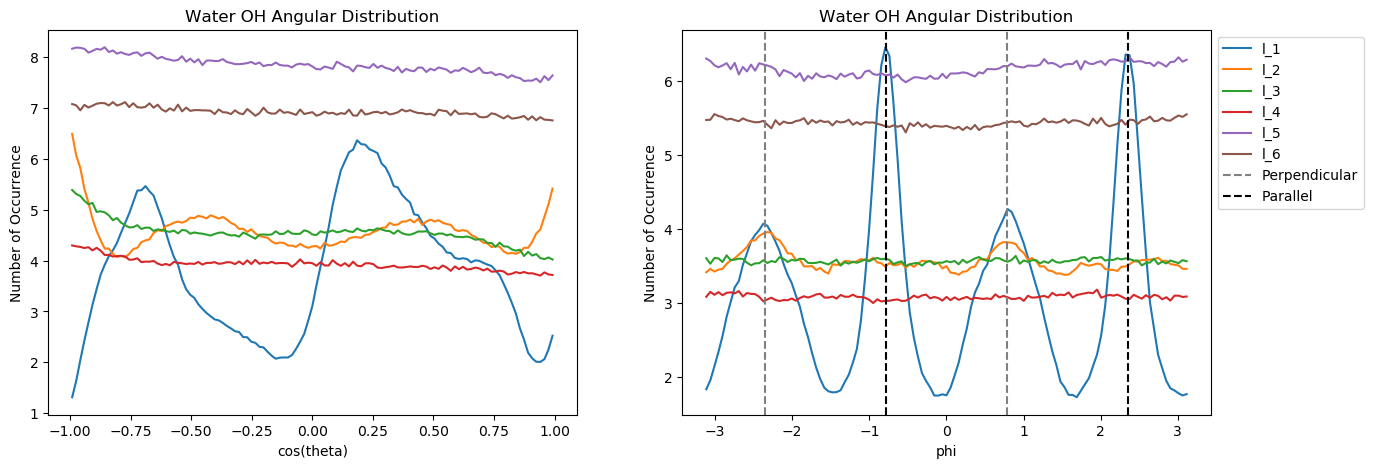

In [24]:
# Set up subplots with 1 row and 3 columns

hist_category='water'

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'

# Iterate through the axes and plot on each
for ax, name_internal, x_name in  zip(axes, name_internals, x_labels):
    for l in layer_bins.keys():
        if all(element == 0 for element in eval(name_internal+str_hist+hist_category)[l]):
            continue
        else:
            ax.plot( eval(name_internal+str_bins_centers)  , eval(name_internal+str_hist+hist_category)[l]/t, label=l  ) 
            ax.set_title('Water OH Angular Distribution')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Number of Occurrence')
ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
ax.axvline(x=-2.3562, color='grey', linestyle='--')
ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
ax.axvline(x=-0.7854, color='black', linestyle='--'  )    
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
#plt.tight_layout()

plt.savefig(f"angular_Water_OH", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

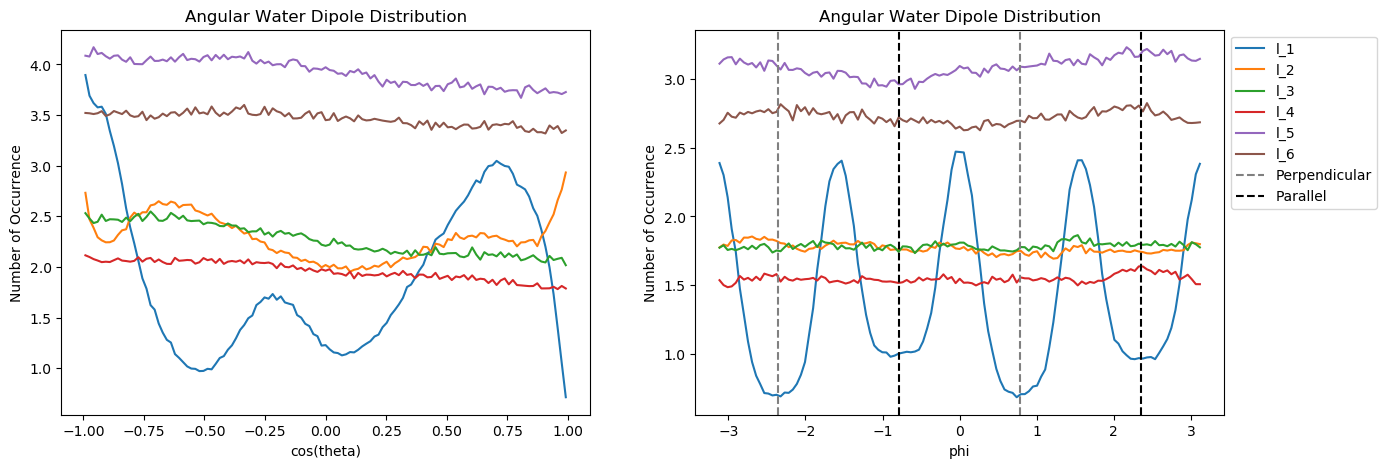

In [25]:
# Set up subplots with 1 row and 3 columns

hist_category='dipole'

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'

# Iterate through the axes and plot on each
for ax, name_internal, x_name in  zip(axes, name_internals, x_labels):
    for l in layer_bins.keys():
        if all(element == 0 for element in eval(name_internal+str_hist+hist_category)[l]):
            continue
        else:
               
            ax.plot( eval(name_internal+str_bins_centers)  , eval(name_internal+str_hist+hist_category)[l]/t, label=l  ) 
            ax.set_title('Angular Water Dipole Distribution')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Number of Occurrence')
ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
ax.axvline(x=-2.3562, color='grey', linestyle='--')
ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
ax.axvline(x=-0.7854, color='black', linestyle='--'  )

ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
#plt.tight_layout()
plt.savefig(f"angular_Water_dipole", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

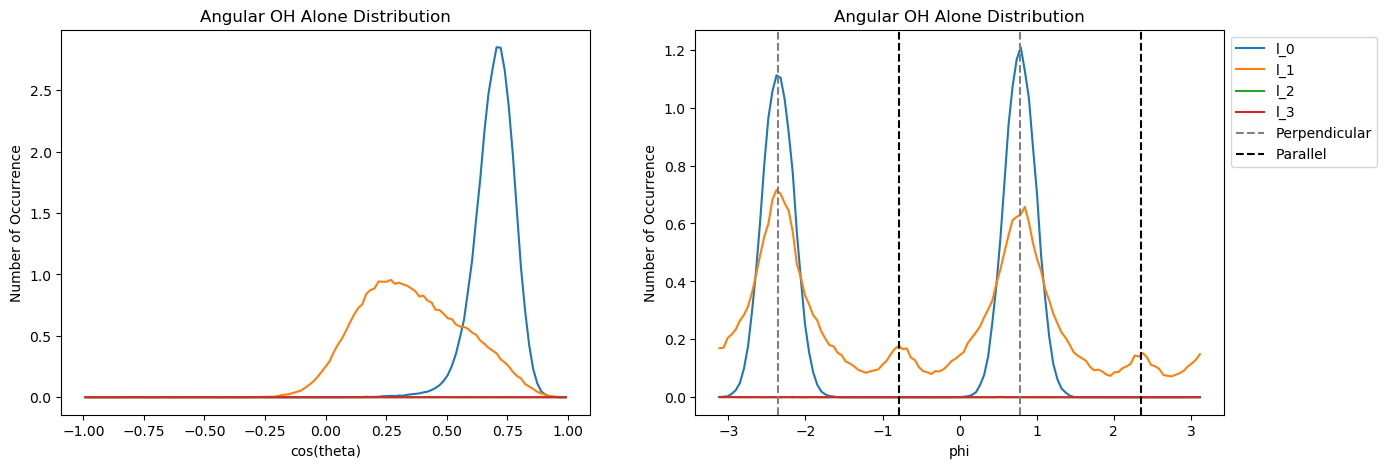

In [26]:
# Set up subplots with 1 row and 3 columns

hist_category='OH'

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

name_internals=[ 'theta', 'phi']
x_labels= [ 'cos(theta)', 'phi']
str_hist='_hist_'
str_bins_centers='_bins_centers'

# Iterate through the axes and plot on each
for ax, name_internal, x_name in  zip(axes, name_internals, x_labels):
    for l in layer_bins.keys():
        if all(element == 0 for element in eval(name_internal+str_hist+hist_category)[l]):
            continue
        else:
            ax.plot( eval(name_internal+str_bins_centers)  , eval(name_internal+str_hist+hist_category)[l]/t, label=l  ) 
            ax.set_title('Angular OH Alone Distribution')
            ax.set_xlabel(x_name)
            ax.set_ylabel('Number of Occurrence')
ax.axvline(x=0.7854, color='grey', linestyle='--', label='Perpendicular')
ax.axvline(x=-2.3562, color='grey', linestyle='--')
ax.axvline(x=2.3562, color='black', linestyle='--' , label='Parallel' )  
ax.axvline(x=-0.7854, color='black', linestyle='--'  )
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
# Adjust layout for better spacing
#plt.tight_layout()
plt.savefig(f"angular_OH_alone", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)
# Show the plots
plt.show()

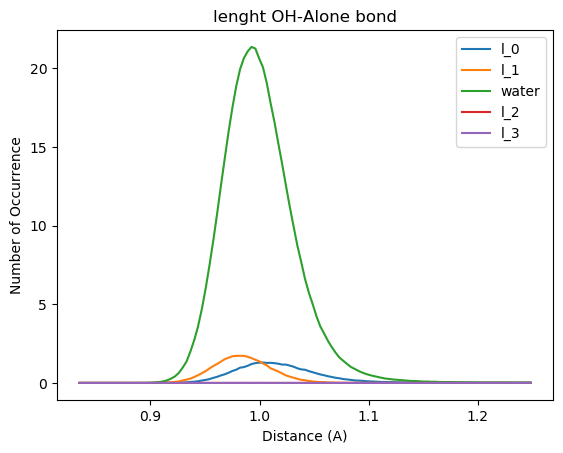

In [27]:
i=0
for l in layer_bins.keys():

    if all(element == 0 for element in  rho_hist_OH[l]):
        continue
    else:
        plt.plot(rho_bins_centers, rho_hist_OH[l]/(t), label=l)
        
        #plt.plot(theta_bins_centers, theta_hist_water[l]/(t), label=l)
        plt.title( "lenght OH-Alone bond")
        plt.xlabel("Distance (A)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()
    if i ==1:
       plt.plot(rho_bins_centers, rho_hist_water[l]/(t),label='water')
    i+=1
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
#plt.savefig(f"bond_lenghts", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)


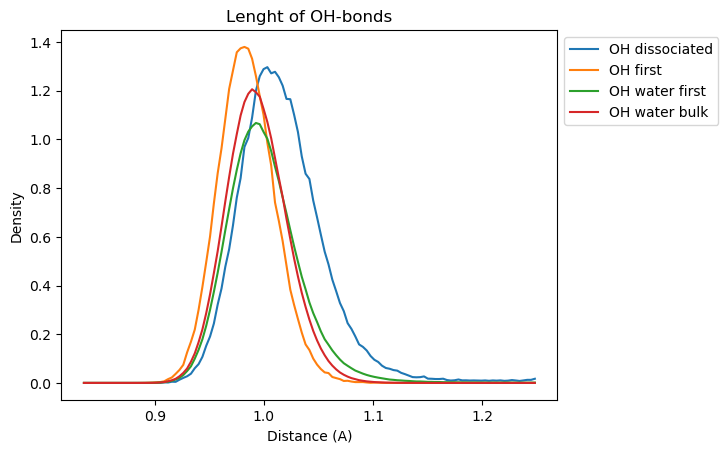

In [28]:

plt.plot(rho_bins_centers, rho_hist_OH['l_0']/(t), label='OH dissociated')
plt.plot(rho_bins_centers, rho_hist_OH['l_1']/(t)*0.8, label='OH first')
plt.plot(rho_bins_centers, rho_hist_water['l_1']/(t)/20,label='OH water first')
plt.plot(rho_bins_centers, rho_hist_water['l_6']/(t)/35,label='OH water bulk')

plt.title( "Lenght of OH-bonds")
plt.xlabel("Distance (A)")
plt.ylabel("Density")


plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.savefig(f"bond_lenghts", bbox_inches="tight", facecolor="white", transparent=True, dpi=200)


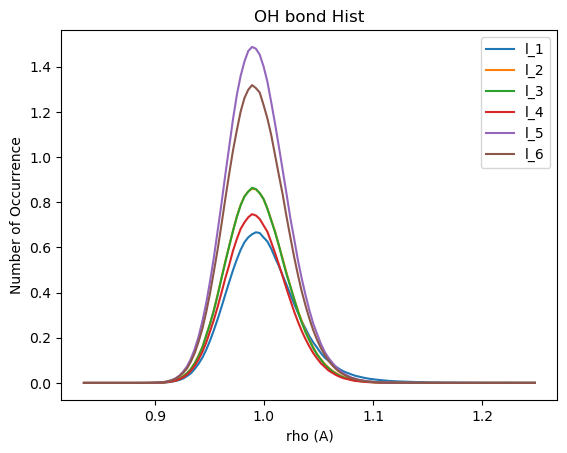

In [29]:

for name in layer_bins.keys():
    if all(element == 0 for element in  rho_hist_water[name]):
        continue
    else:
        plt.plot(rho_bins_centers, rho_hist_water[name]/(t*2*f), label=name)
        #plt.plot(theta_bins_centers, theta_hist_water[name]/(t))
        #plt.plot(theta_bins_centers, theta_hist_dipole[name]/(t), label=name)
        plt.title( "OH bond Hist")
        plt.xlabel("rho (A)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()


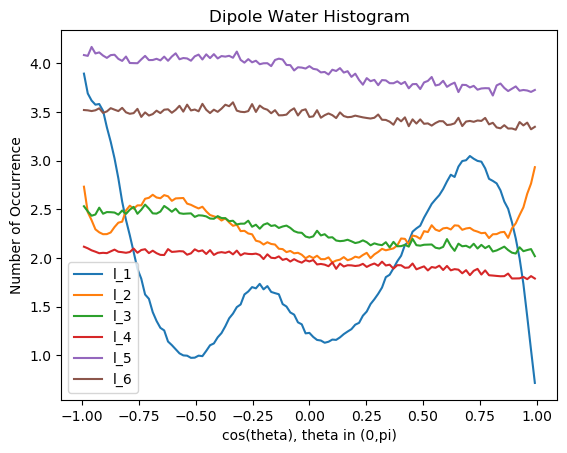

In [30]:

for name in layer_bins.keys():
    if all(element == 0 for element in  rho_hist_water[name]):
        continue
    else:
        #plt.plot(rho_bins_centers, rho_hist_water[name]/(t), label='O', color='r')
        #plt.plot(theta_bins_centers, theta_hist_water[name]/(t))
        plt.plot(theta_bins_centers, theta_hist_dipole[name]/(t), label=name)
        plt.title( "Dipole Water Histogram")
        plt.xlabel("cos(theta), theta in (0,pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()
    

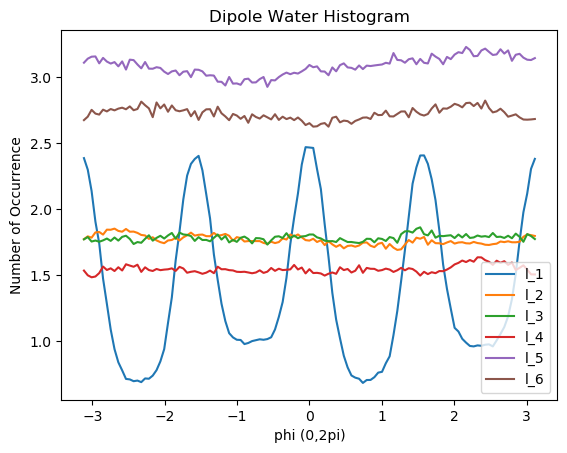

In [31]:
for name in layer_bins.keys():
    if all(element == 0 for element in  rho_hist_water[name]):
        continue
    else:
        #plt.plot(rho_bins_centers, rho_hist_water[name]/(t), label='O', color='r')
        #plt.plot(theta_bins_centers, theta_hist_water[name]/(t))
        plt.plot(phi_bins_centers, phi_hist_dipole[name]/(t), label=name)
        plt.title( "Dipole Water Histogram")
        plt.xlabel("phi (0,2pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()

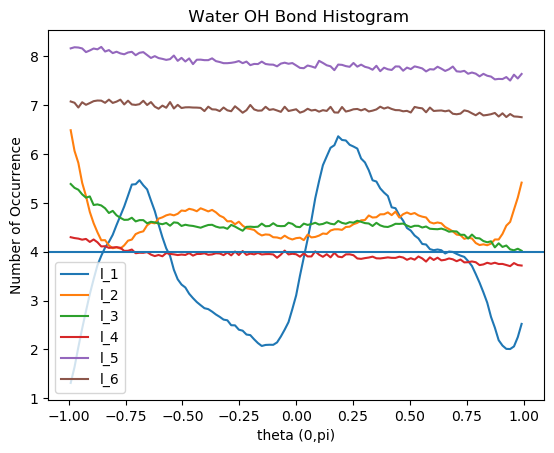

In [32]:
for name in layer_bins.keys():
    if all(element == 0 for element in  theta_hist_water[name]):
        continue
    else:
        #plt.plot(rho_bins_centers, rho_hist_water[name]/(t), label='O', color='r')
        plt.plot(theta_bins_centers, theta_hist_water[name]/(t), label=name)
        #plt.plot(phi_bins_centers, phi_hist_dipole[name]/(t), label=name)
        plt.title( " Water OH Bond Histogram")
        plt.xlabel("theta (0,pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()
plt.axhline(4)

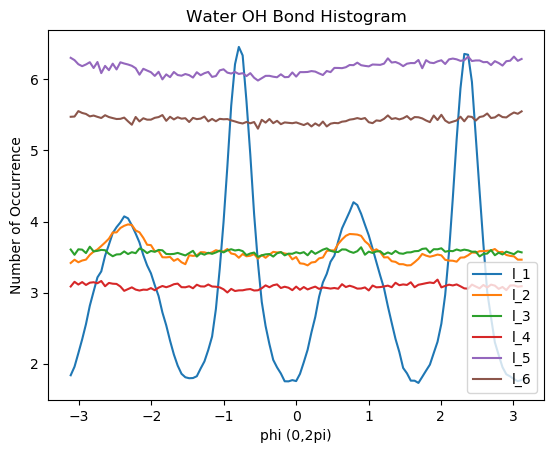

In [33]:
for name in layer_bins.keys():
    if all(element == 0 for element in  phi_hist_water[name]):
        continue
    else:
        #plt.plot(rho_bins_centers, rho_hist_water[name]/(t), label='O', color='r')
        plt.plot(phi_bins_centers, phi_hist_water[name]/(t), label=name)
        #plt.plot(phi_bins_centers, phi_hist_dipole[name]/(t), label=name)
        plt.title( "Water OH Bond Histogram")
        plt.xlabel("phi (0,2pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()

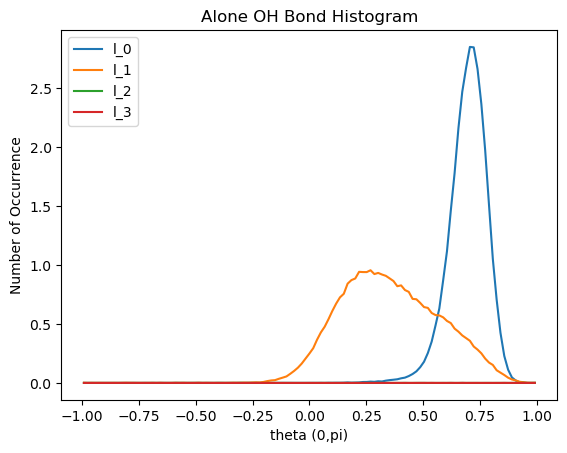

In [34]:
for name in layer_bins.keys():
    if all(element == 0 for element in  theta_hist_OH[name]):
        continue
    else:
        #plt.plot(rho_bins_centers, rho_hist_water[name]/(t), label='O', color='r')
        plt.plot(theta_bins_centers, theta_hist_OH[name]/(t), label=name)
        #plt.plot(phi_bins_centers, phi_hist_dipole[name]/(t), label=name)
        plt.title( "Alone OH Bond Histogram")
        plt.xlabel("theta (0,pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.ylim(0,0.001)
        #plt.show()

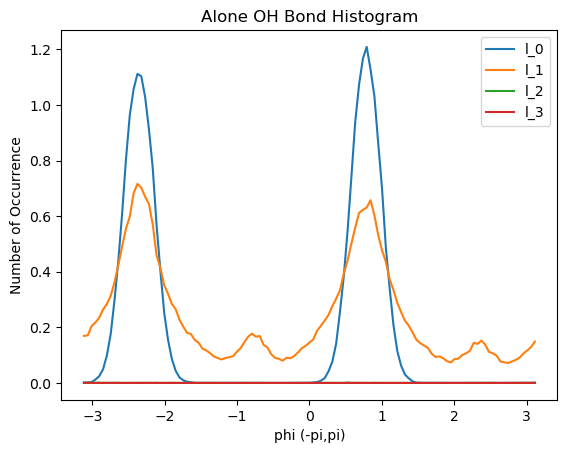

In [35]:
for name in layer_bins.keys():
    if all(element == 0 for element in  phi_hist_OH[name]):
        continue
    else:
        plt.plot(phi_bins_centers, phi_hist_OH[name]/(t), label=name)
        #plt.plot(phi_bins_centers, phi_hist_dipole[name]/(t), label=name)
        plt.title( "Alone OH Bond Histogram")
        plt.xlabel("phi (-pi,pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()

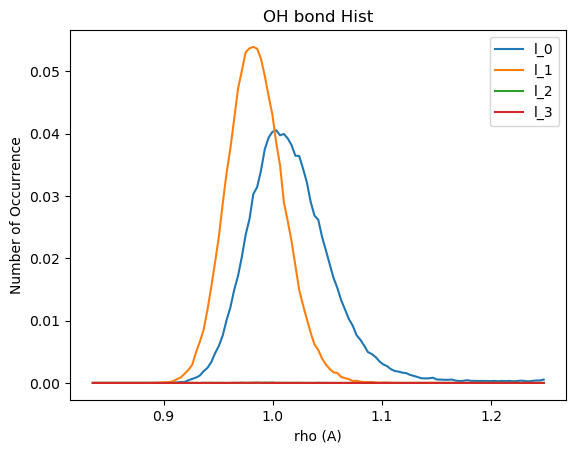

In [36]:

for name in layer_bins.keys():
    if all(element == 0 for element in  rho_hist_OH[name]):
        continue
    else:
        plt.plot(rho_bins_centers, rho_hist_OH[name]/(t*2*f), label=name)
        #plt.plot(theta_bins_centers, theta_hist_water[name]/(t))
        #plt.plot(theta_bins_centers, theta_hist_dipole[name]/(t), label=name)
        plt.title( "OH bond Hist")
        plt.xlabel("rho (A)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()

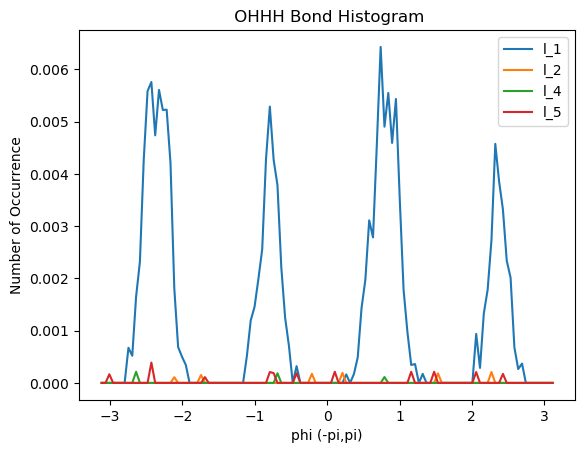

In [37]:
for name in layer_bins.keys():
    if all(element == 0 for element in  phi_hist_OHHH[name]):
        continue
    else:
        plt.plot(phi_bins_centers, phi_hist_OHHH[name]/(t), label=name)
        #plt.plot(phi_bins_centers, phi_hist_dipole[name]/(t), label=name)
        plt.title( " OHHH Bond Histogram")
        plt.xlabel("phi (-pi,pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()

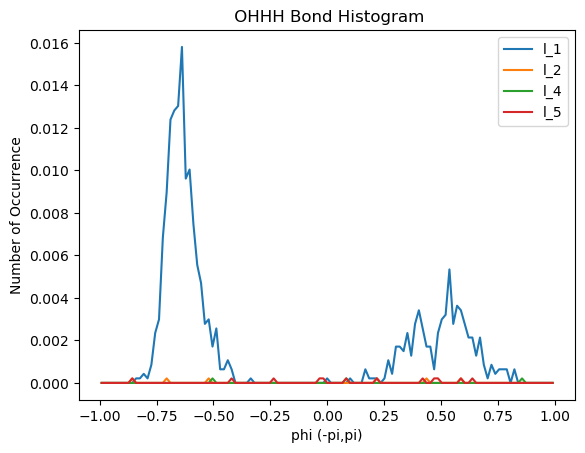

In [38]:
for name in layer_bins.keys():
    if all(element == 0 for element in  theta_hist_OHHH[name]):
        continue
    else:
        plt.plot(theta_bins_centers, theta_hist_OHHH[name]/(t), label=name)
        #plt.plot(phi_bins_centers, phi_hist_dipole[name]/(t), label=name)
        plt.title( " OHHH Bond Histogram")
        plt.xlabel("phi (-pi,pi)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()

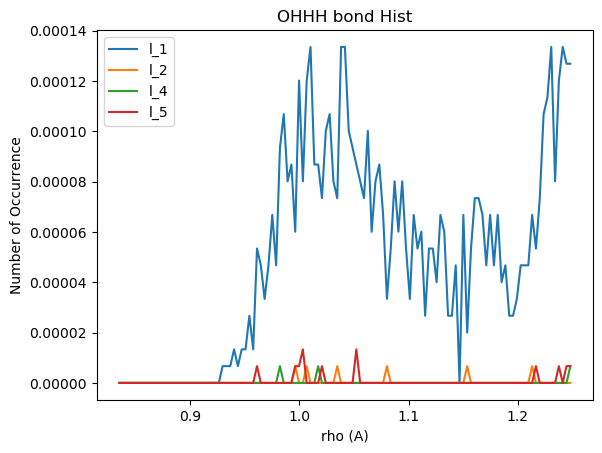

In [39]:
for name in layer_bins.keys():
    if all(element == 0 for element in  rho_hist_OHHH[name]):
        continue
    else:
        plt.plot(rho_bins_centers, rho_hist_OHHH[name]/(t*2*f), label=name)
        #plt.plot(theta_bins_centers, theta_hist_water[name]/(t))
        #plt.plot(theta_bins_centers, theta_hist_dipole[name]/(t), label=name)
        plt.title( "OHHH bond Hist")
        plt.xlabel("rho (A)")
        plt.ylabel("Number of Occurrence")
        plt.legend()
        #plt.show()

In [40]:

#BULK WATER



L=12.42
box_water=np.array([L,L,L])
delta=1.19
trj_bulk="./bulk_water/trjshort.dump"  
t=0

#histograms
n_bins_water=50
#cutoff_rho=2*delta
layer_bulk=[0,L]
# Define your bins
layer_bulk_bin = {
    "bulk_like" : lambda x:  True
}
    
#initilize  rho theta and phi bins and bins centers
rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta)
#initialize histograms with zeros
rho_hist_OH , theta_hist_OH, phi_hist_OH  =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_water , theta_hist_water, phi_hist_water =init_hist_rho_theta_phi(layer_bins, n_bins)
rho_hist_dipole , theta_hist_dipole, phi_hist_dipole =init_hist_rho_theta_phi(layer_bins, n_bins)   
rho_hist_OHHH , theta_hist_OHHH, phi_hist_OHHH =init_hist_rho_theta_phi(layer_bins, n_bins)  
    

for t_slice in aio.iread(trj_bulk,format='lammps-dump-text'):
    
     #parsing
     H, O = parser_water_bulk(t_slice)
     
  
     #H_u/d_index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O 
     #makes a tree of Hs
     tree = cKDTree(data=H, leafsize=H.shape[0], boxsize= box_water)
     #assign every H to an O within the cutoff and make the list of list H
     H_indx = tree.query_ball_point(O, delta)   
     
   
     dipole, OH_water , OH, O_HHH, O_alone=get_O_cartesian_OH_internal(H_indx, O, H, L,L,L, t)
     
     
 
     #use the info of the Oxygen to group the OH by their heights: output is now only OH in internal
     dipole_z_grouped= OH_z_layer_grouping(dipole, layer_bulk_bin)
     OH_water_z_grouped= OH_z_layer_grouping(OH_water, layer_bulk_bin)
     OH_z_grouped= OH_z_layer_grouping(OH, layer_bulk_bin)
     if len(O_HHH) != 0:
          O_HHH_z_grouped= OH_z_layer_grouping(O_HHH, layer_bulk_bin)
     
     
   
     rho_hist_OH,     theta_hist_OH,     phi_hist_OH     = sum_hist_rho_theta_phi(OH_z_grouped, rho_hist_OH, theta_hist_OH, phi_hist_OH, rho_bins, theta_bins, phi_bins )
     rho_hist_water,  theta_hist_water,  phi_hist_water  = sum_hist_rho_theta_phi(OH_water_z_grouped, rho_hist_water, theta_hist_water, phi_hist_water, rho_bins, theta_bins, phi_bins )
     rho_hist_dipole, theta_hist_dipole, phi_hist_dipole = sum_hist_rho_theta_phi(dipole_z_grouped, rho_hist_dipole, theta_hist_dipole, phi_hist_dipole, rho_bins, theta_bins, phi_bins )
     
     if len(O_HHH) != 0:
          rho_hist_OHHH , theta_hist_OHHH, phi_hist_OHHH      = sum_hist_rho_theta_phi(O_HHH_z_grouped, rho_hist_OHHH, theta_hist_OHHH, phi_hist_OHHH, rho_bins, theta_bins, phi_bins )
     t+=1
     
     

TypeError: sum_hist_rho_theta_phi() missing 1 required positional argument: 'density_bool'

In [ ]:
#BULK TRANSLATED (NOT WORKING)
from scipy.spatial import cKDTree


box_size_center=np.array([L_x,L_y,L_z])
delta=1.25

#histograms
n_bins=150

offset=(z_interval_u[0]-z_interval_d[0])/2
layers=np.linspace(offset, L_z-offset,11)
names=["l_"+str(i) for i in np.arange(1,11)]
layer_bins_centered=dict_bins_maker(names,layers)

#initilize  rho theta and phi bins and bins centers
rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta)
#initialize histograms with zeros
rho_hist_OH , theta_hist_OH, phi_hist_OH   =init_hist_rho_theta_phi(layer_bins_centered, n_bins)
rho_hist_water , theta_hist_water, phi_hist_water =init_hist_rho_theta_phi(layer_bins_centered, n_bins)
rho_hist_dipole , theta_hist_dipole, phi_hist_dipole =init_hist_rho_theta_phi(layer_bins_centered, n_bins)   
rho_hist_OHHH , theta_hist_OHHH, phi_hist_OHHH =init_hist_rho_theta_phi(layer_bins_centered, n_bins)  
    
    
t=0
for t_slice in aio.iread(trj,format='lammps-dump-text'):
    
     #parsing
     H, O,  OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d = parser_full_coverage(t_slice,  z_interval_u, z_interval_d,  N_water, N_OS, N_FeS, N_FeS2)
     
     if t %10 == 0:   #it does every 10 steps
          #get layer update infos of surfaces 
          
          #first 
          S_u, S_u_min, S_u_max =get_layer_z(np.concatenate((OS_u,FeS_u),axis=0 ))
          S_d, S_d_min, S_d_max =get_layer_z(np.concatenate((OS_d,FeS_d),axis=0 )) 
          
          #oct/tet raws
          diag_raw_u=get_diagonal_O_raws(OS_u, control_u, diag_lenght, 1 )
          diag_raw_d=get_diagonal_O_raws(OS_d, control_d, diag_lenght, 1 )
     
     #add oxygen at surface to get the OH bond of dissociation
     all_O=np.concatenate((O,OS_u,OS_d))
      
      
     
     O_center=recenter_wrap_bulk_water(all_O, S_u, S_d, L_x, L_y, L_z)

     H_center=recenter_wrap_bulk_water(H, S_u, S_d, L_x, L_y, L_z)
    
     
     #H_u/d_index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O 
     #makes a tree of Hs
     tree = cKDTree(data=H_center, leafsize=H_center.shape[0], boxsize= box_size_center)
     #assign every H to an O within the cutoff and make the list of list H
     H_indx = tree.query_ball_point(O_center, delta)   

   
    
   
     dipole, OH_water , OH, O_HHH, O_alone=get_O_cartesian_OH_internal(H_indx, O_center, H_center, L_x,L_y, 100, t)
     
     
 
     #use the info of the Oxygen to group the OH by their heights: output is now only OH in internal
     dipole_z_grouped= OH_z_layer_grouping(dipole, layer_bins_centered)
     OH_water_z_grouped= OH_z_layer_grouping(OH_water, layer_bins_centered)
     OH_z_grouped= OH_z_layer_grouping(OH,layer_bins_centered)
     if len(O_HHH) != 0:
          O_HHH_z_grouped= OH_z_layer_grouping(O_HHH, layer_bins_centered)
     
     
   
     rho_hist_OH,     theta_hist_OH,     phi_hist_OH     = sum_hist_rho_theta_phi(OH_z_grouped, rho_hist_OH, theta_hist_OH, phi_hist_OH, rho_bins, theta_bins, phi_bins )
     rho_hist_water,  theta_hist_water,  phi_hist_water  = sum_hist_rho_theta_phi(OH_water_z_grouped, rho_hist_water, theta_hist_water, phi_hist_water, rho_bins, theta_bins, phi_bins )
     rho_hist_dipole, theta_hist_dipole, phi_hist_dipole = sum_hist_rho_theta_phi(dipole_z_grouped, rho_hist_dipole, theta_hist_dipole, phi_hist_dipole, rho_bins, theta_bins, phi_bins )
     
     if len(O_HHH) != 0:
          rho_hist_OHHH , theta_hist_OHHH, phi_hist_OHHH      = sum_hist_rho_theta_phi(O_HHH_z_grouped, rho_hist_OHHH, theta_hist_OHHH, phi_hist_OHHH, rho_bins, theta_bins, phi_bins )
   
     t+=1

     